# Comparison of Fit Results
This notebook loads and compares the fit histories and results for the following runs:
- **27318914**: Probabilistic Simulation target, $dE/dx$ prior weight = 0.5, Birks' k ($k_b$) fixed
- **27339284**: Probabilistic Simulation target, $dE/dx$ prior weight = 0.0, Birks' k ($k_b$) fixed
- **27347468**: Standard/Stochastic Simulation target, $dE/dx$ prior weight = 0.5, Birks' k ($k_b$) fixed
- **27354407**: (Gracefully skipped if OOM'ed) Probabilistic Simulation target, $dE/dx$ prior weight = 0.5, Birks' k ($k_b$) fixed

It averages results across all 5 seeds for each run to compute robust metrics and trajectories.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import comparison utilities
from optimize.compare_fits import (
    compare_runs, 
    plot_loss_convergence, 
    plot_param_convergence, 
    plot_parameter_biases, 
    plot_dedx_mae, 
    plot_dedx_residuals_comparison, 
    plot_dedx_histories
)

# Define the runs to compare
runs = ["27318914", "27339284", "27347468", "27354407"]

# Set default smoothing window
smooth_win = 100

## 1. Load Data
Load fit result files from `fit_result/` for each run.

In [2]:
results, df_configs, df_params = compare_runs(runs)

Loading 5 seeds for run 27318914...


ERROR:2026-05-29 02:49:51,486:jax._src.xla_bridge:444: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/jax/_src/xla_bridge.py", line 442, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/usr/local/lib/python3.10/dist-packages/jax_plugins/xla_cuda12/__init__.py", line 324, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/usr/local/lib/python3.10/dist-packages/jax_plugins/xla_cuda12/__init__.py", line 281, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CUDA libraries.


Loading 5 seeds for run 27339284...


Loading 5 seeds for run 27347468...


Skipping run 27354407 due to error: No pickle files found for run 27354407 in fit_result


## 2. Configuration Comparison
Compare varying parameters between the runs to see how they differ.

In [3]:
# Find columns that have varying values
varying_cols = [col for col in df_configs.columns if df_configs[col].nunique() > 1]
if varying_cols:
    display(df_configs[varying_cols])
else:
    print("All runs have identical configurations.")
    display(df_configs)

,seed,out_label,test_name,probabilistic_sampling_target,dedx_prior_weight
27318914,5,true_throughmuons_6par_dedxfit_priw0.5_dlr1e-2...,fit_noise_dedx_27318914,True,0.5
27339284,1,true_throughmuons_6par_dedxfit_priw0_dlr1e-2_d...,fit_noise_dedx_27339284,True,0.0
27347468,1,true_throughmuons_6par_dedxfit_priw0.5_dlr1e-2...,fit_noise_dedx_27347468,False,0.5


## 3. Fitted Parameters Summary Table
Compare final fitted values against true target values. Bias is computed as `Fitted - Target`.

In [4]:
# Format the table for display
pd.set_option('display.max_rows', 100)
display(df_params)

,run_id,parameter,target,init,final_val,bias,bias_rel_percent,dEdx_MAE,seeds
0,27318914,Ab,0.831857,0.800000,8.3125e-01 ± 2.5532e-02,-6.024529e-04,-0.072423,0.080402,5
1,27318914,eField,0.507447,0.500000,5.0747e-01 ± 2.9330e-02,2.484773e-05,0.004897,0.080402,5
2,27318914,tran_diff,0.000008,0.000009,8.0816e-06 ± 3.3839e-06,4.139407e-08,0.514841,0.080402,5
3,27318914,long_diff,0.000006,0.000004,5.9522e-06 ± 1.4402e-06,-8.250037e-08,-1.367106,0.080402,5
4,27318914,lifetime,2881.589595,2200.000000,2.6651e+03 ± 1.0112e+03,-2.165347e+02,-7.514419,0.080402,5
5,27318914,shift_x,-0.031082,0.000000,-3.1133e-02 ± 1.2802e-01,-5.122311e-05,0.164802,0.080402,5
6,27318914,shift_y,-0.021236,0.000000,-2.2056e-02 ± 1.5367e-01,-8.196497e-04,3.859633,0.080402,5
7,27318914,shift_z,-0.070688,0.000000,-7.2074e-02 ± 9.4684e-02,-1.386006e-03,1.960727,0.080402,5
8,27318914,dedx_prior,NaN,NaN,-1.3431e+02 ± 4.2357e+00,NaN,NaN,0.080402,5
9,27318914,dedx_barrier,NaN,NaN,0.0000e+00 ± 0.0000e+00,NaN,NaN,0.080402,5


## 4. Loss Convergence
Plot the loss evolution over iterations for each run (averaged over the 5 seeds, with shaded standard deviation, smoothed over 100 iterations).

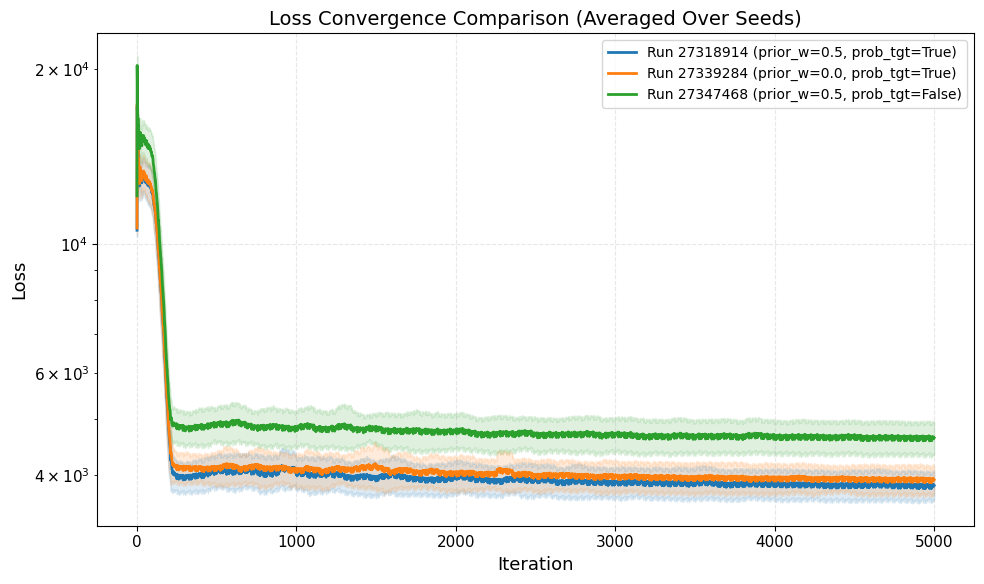

In [5]:
plot_loss_convergence(results, smoothing_window=smooth_win)
plt.show()

## 5. Parameter Convergence Grid
Show the convergence of all fitted parameters over iterations compared to their target values (smoothed over 100 iterations).

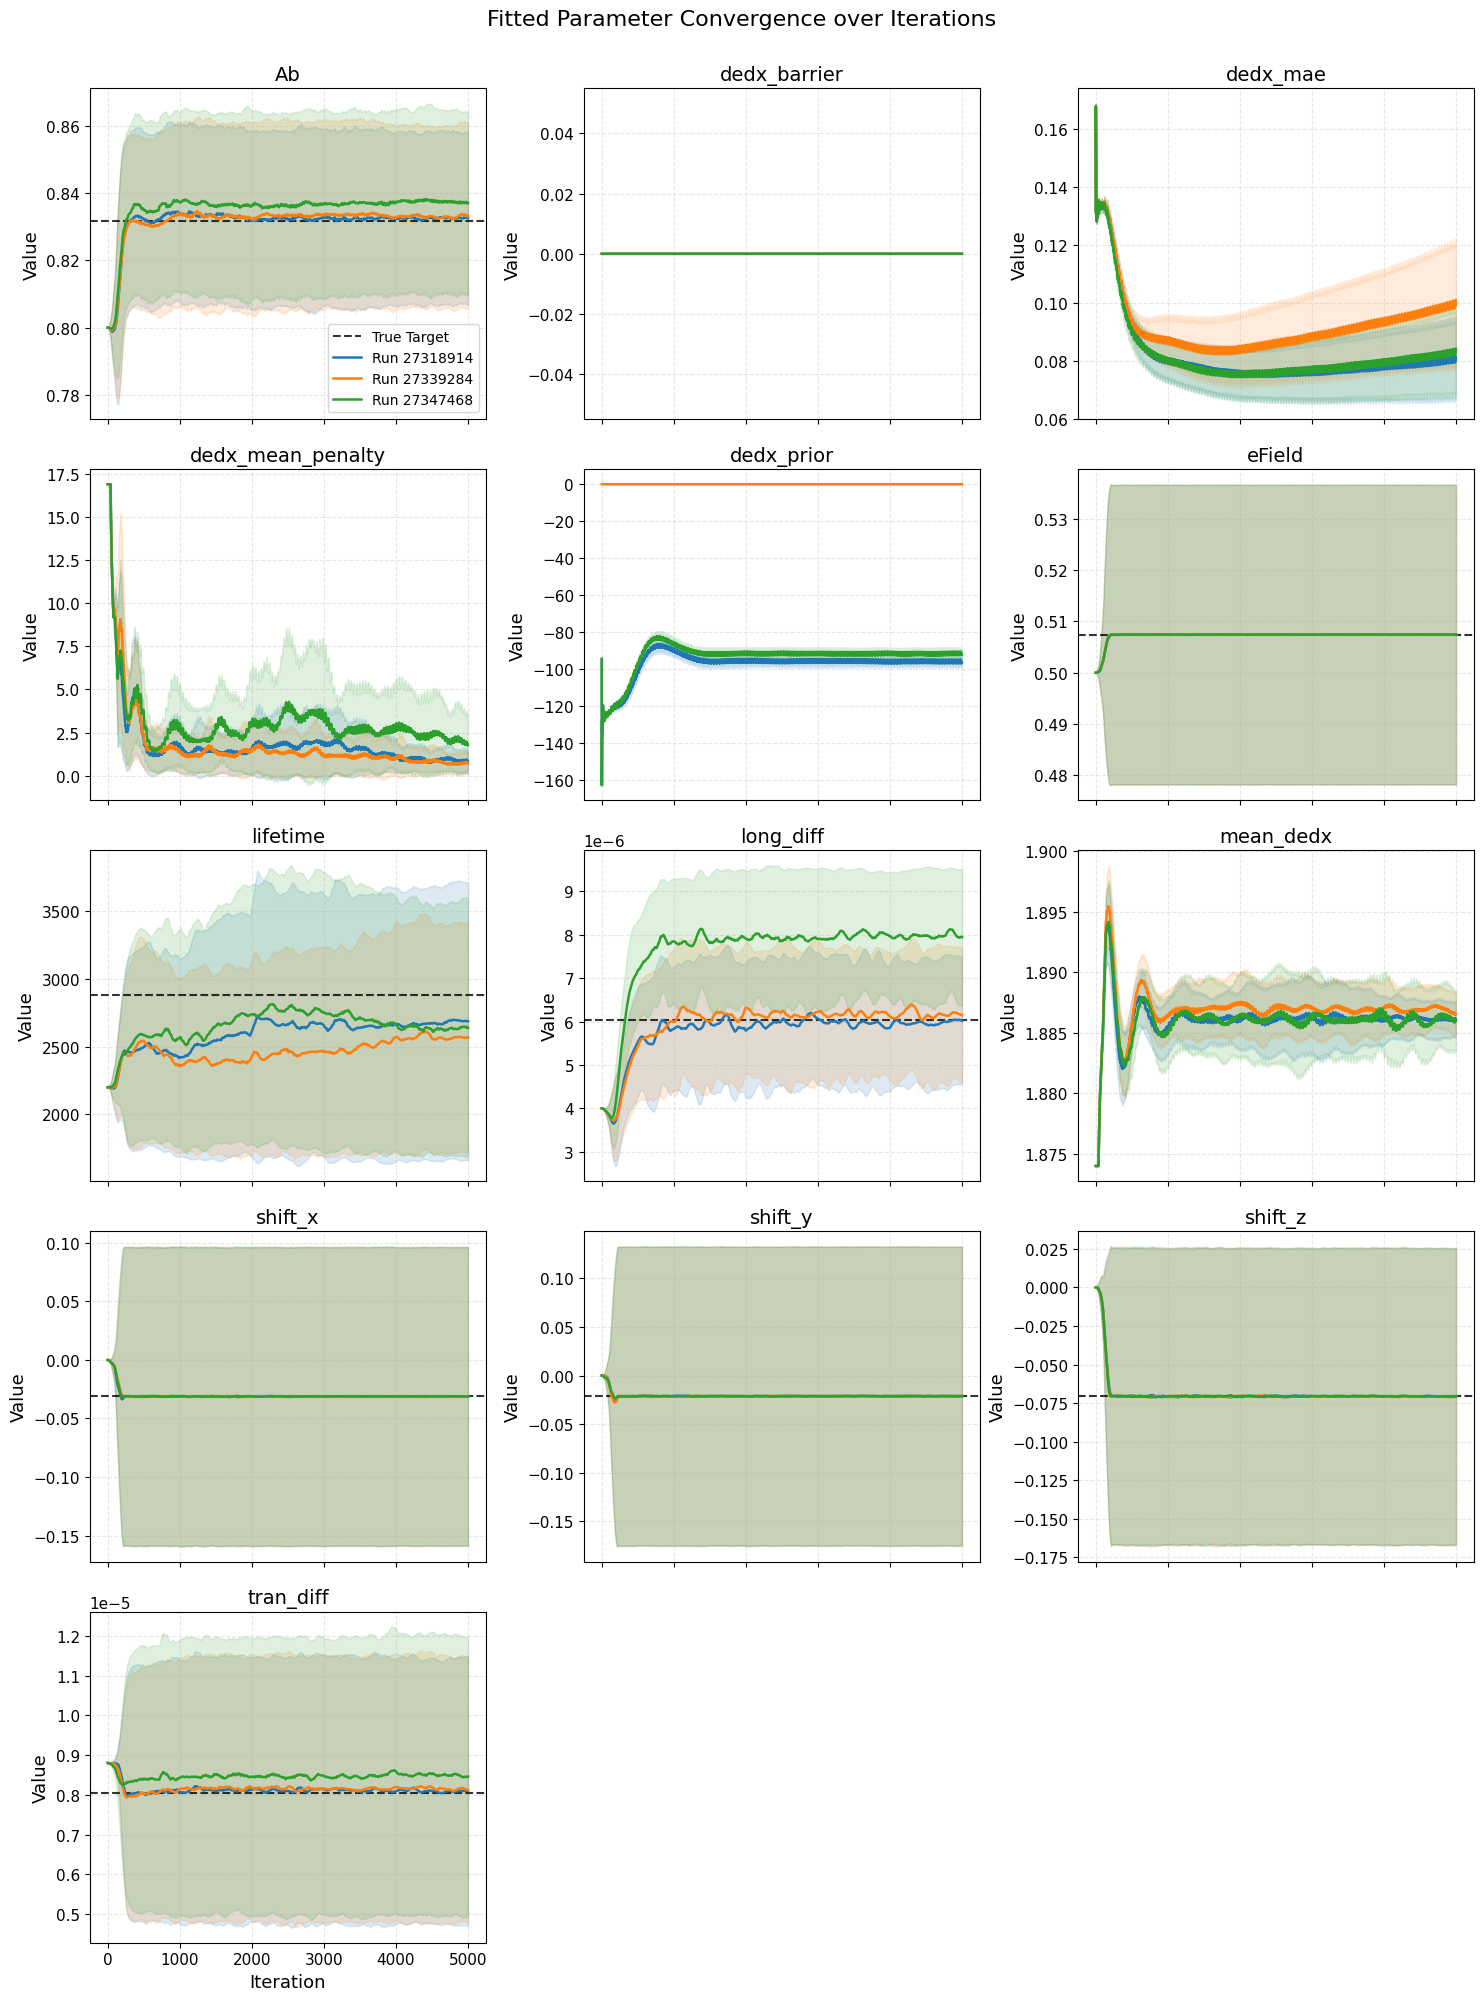

In [6]:
plot_param_convergence(results, smoothing_window=smooth_win)
plt.show()

## 6. Parameter Relative Biases
Bar chart displaying the final relative biases for all fitted parameters (with error bars representing standard deviation across seeds).

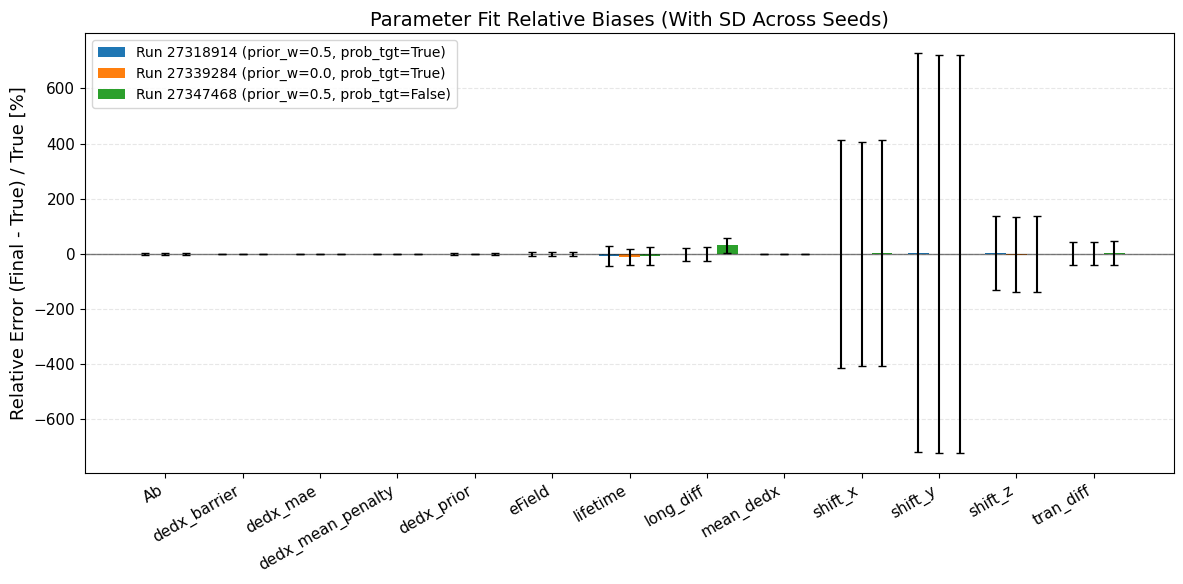

In [7]:
plot_parameter_biases(results)
plt.show()

## 7. dEdx Fit MAE
Bar chart showing the average Mean Absolute Error (MAE) of the fitted $dE/dx$ profiles (lower is better).

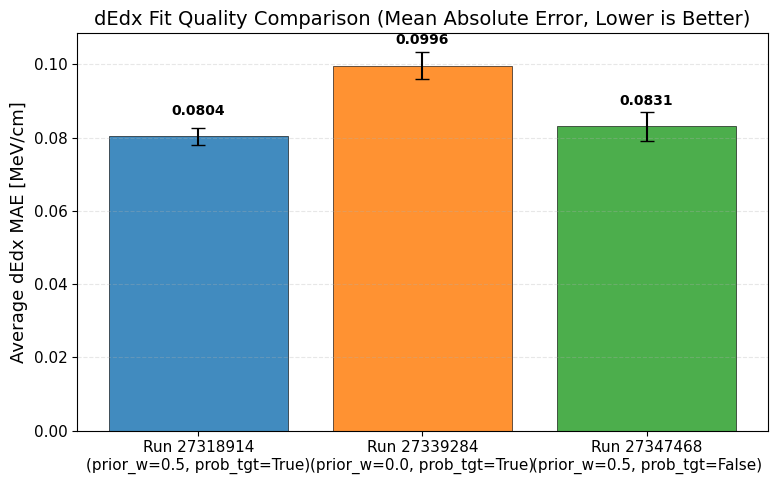

In [8]:
plot_dedx_mae(results)
plt.show()

## 8. dEdx Residuals Distribution
Overlay the probability density distribution of $dE/dx$ residuals (Fitted - True) across all track segments and seeds for each run.

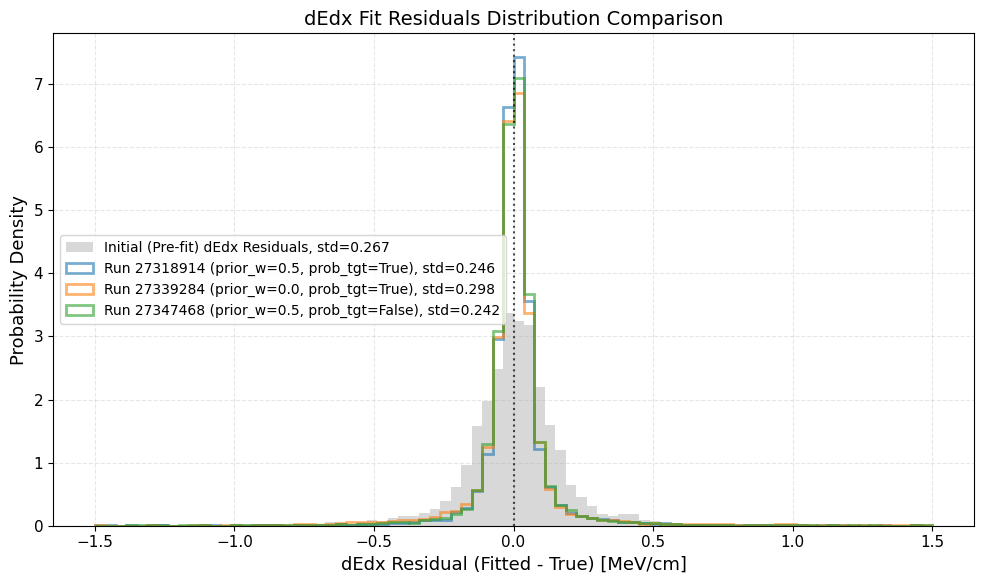

In [9]:
plot_dedx_residuals_comparison(results)
plt.show()

## 9. dEdx Convergence Histories
Plot dEdx MAE and weighted mean dEdx convergence histories over iterations (smoothed over 100 iterations).

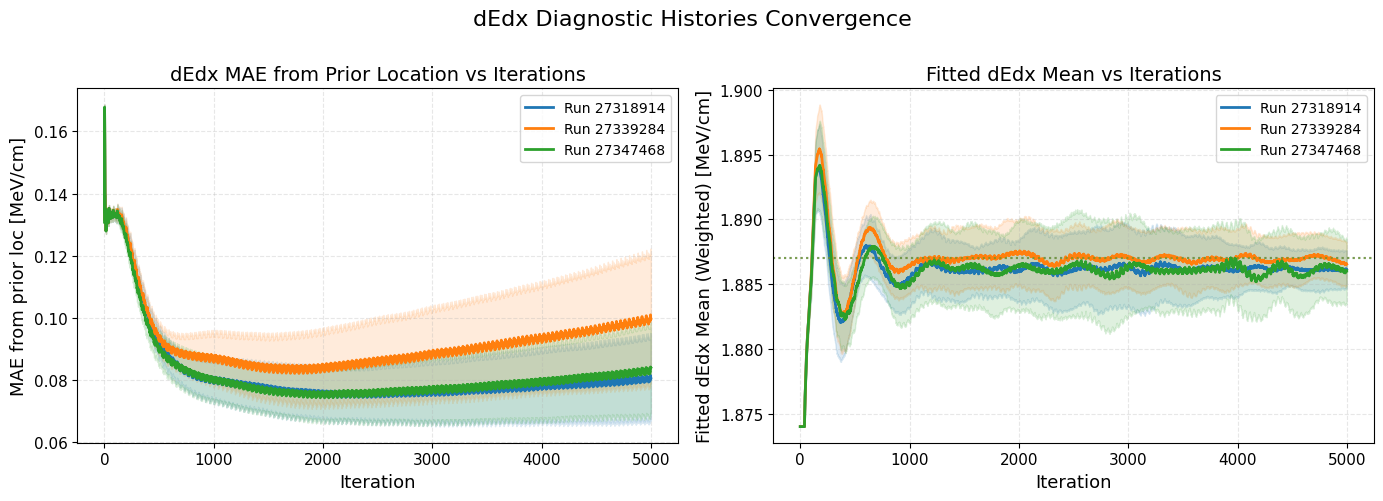

In [10]:
plot_dedx_histories(results, smoothing_window=smooth_win)
plt.show()